<a href="https://colab.research.google.com/github/charliemzliu/STA2112-Project/blob/main/notebooks/Main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import importlib

!git clone https://github.com/charliemzliu/STA2112-Project.git
%cd STA2112-Project
import src.InterventionData as intervention
import src.SEM_Simulation as sem
import src.hypothesis_tests as hypo

importlib.reload(intervention)
importlib.reload(sem)
importlib.reload(hypo)

InterventionData = intervention.InterventionData
Linear_Gussian_SEM = sem.Linear_Gussian_SEM
Linear_Gussian_DO = sem.Linear_Gussian_DO
ICP = hypo.invariant_prediction


Cloning into 'STA2112-Project'...
remote: Enumerating objects: 57, done.
remote: Counting objects: 100% (57/57), done.
remote: Compressing objects: 100% (46/46), done.
remote: Total 57 (delta 13), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (57/57), 73.13 KiB | 5.22 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/STA2112-Project/STA2112-Project/STA2112-Project/STA2112-Project


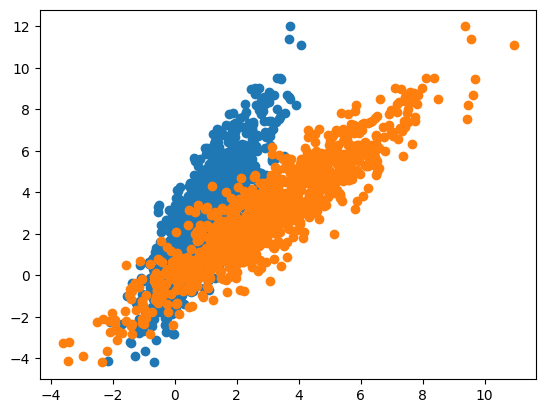

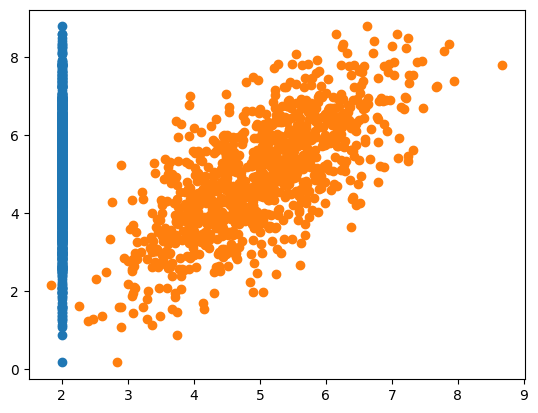

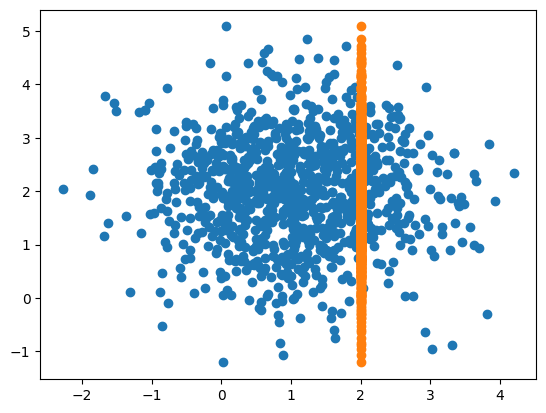

[(1,), (0, 1)]
{(): 1.2506492553369967e-24, (0,): 3.4898641797662906e-56, (1,): 0.6704175468121379, (0, 1): 0.6731672904684293}


In [10]:
#Simple examples with 2 predictors(p=2+1=3)
#Chain: X1 -> X2 -> Y
Chain_coef = np.array([[0,0,0],
                      [2,0,0],
                      [0,1,0]])
Intervention = [([0],[2]),([1],[2])]
Mean = (1,1,0)
Variance = (1,1,1)

Chain3_Data = Linear_Gussian_DO(size=[1000,1000,1000],p=3,Coeff=Chain_coef,mean=Mean,Variance=Variance,target=2,intervention=Intervention)

plt.scatter(Chain3_Data.X[Chain3_Data.environments == 1,0],Chain3_Data.Y[Chain3_Data.environments == 1])
plt.scatter(Chain3_Data.X[Chain3_Data.environments == 1,1],Chain3_Data.Y[Chain3_Data.environments == 1])
plt.show()


plt.scatter(Chain3_Data.X[Chain3_Data.environments == 2,0],Chain3_Data.Y[Chain3_Data.environments == 2])
plt.scatter(Chain3_Data.X[Chain3_Data.environments == 2,1],Chain3_Data.Y[Chain3_Data.environments == 2])
plt.show()

plt.scatter(Chain3_Data.X[Chain3_Data.environments == 3,0],Chain3_Data.Y[Chain3_Data.environments == 3])
plt.scatter(Chain3_Data.X[Chain3_Data.environments == 3,1],Chain3_Data.Y[Chain3_Data.environments == 3])
plt.show()

Chain3_test1 = ICP(data=Chain3_Data,method="I",alpha=0.05,max_size=None,compute_ci=False)
print(Chain3_test1.accepted_sets)
print(Chain3_test1.pvalues)
print(Chain3_test1.selected)
